In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from io import StringIO
from IPython.display import display

# Configuração visual dos gráficos
plt.style.use("dark_background")
plt.rcParams["figure.figsize"] = (12, 6)

print("Bibliotecas carregadas com sucesso!")



# Endereço oficial do serviço de dados
URL_NASA = (
    "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
)

# Dados que queremos consultar
consulta = """
SELECT pl_name, hostname, sy_dist,
       discoverymethod, disc_year
FROM pscomppars
WHERE sy_dist IS NOT NULL
  AND sy_dist > 0
ORDER BY sy_dist ASC
"""

parametros = {
    "query": consulta,
    "format": "csv"
}

try:
    resposta = requests.get(
        URL_NASA,
        params=parametros,
        timeout=90
    )
    resposta.raise_for_status()

    df = pd.read_csv(StringIO(resposta.text))

    if df.empty or "sy_dist" not in df.columns:
        raise ValueError("A NASA não retornou os dados esperados.")

    print("Dados recebidos do NASA Exoplanet Archive!")
    print("Quantidade de registros:", len(df))

except Exception as erro:
    print("Não foi possível baixar os dados.")
    print("Detalhe:", erro)
    print("Verifique se a Internet está habilitada no Kaggle.")
    raise


Bibliotecas carregadas com sucesso!
Dados recebidos do NASA Exoplanet Archive!
Quantidade de registros: 6423



# 🪐 ExoDistance — Explorador de Distâncias de Exoplanetas

## Objetivo
Consultar dados reais do NASA Exoplanet Archive para:
- Calcular distâncias em anos-luz.
- Pesquisar exoplanetas pelo nome.
- Comparar sistemas planetários.
- Visualizar as distâncias em gráficos.
- Exportar os resultados para CSV.

## Fonte dos dados
NASA Exoplanet Archive — tabela Planetary Systems Composite Parameters.

## Conversão utilizada
1 parsec ≈ 3,26156 anos-luz.


In [10]:

# Fator de conversão astronômica
PARSEC_PARA_ANO_LUZ = 3.26156

# Garantir que a distância seja numérica
df["sy_dist"] = pd.to_numeric(
    df["sy_dist"], errors="coerce"
)

# Remover valores inválidos
df = df.dropna(subset=["pl_name", "sy_dist"])
df = df[df["sy_dist"] > 0].copy()

# Calcular a distância em anos-luz
df["distancia_anos_luz"] = (
    df["sy_dist"] * PARSEC_PARA_ANO_LUZ
)

# Organizar do sistema mais próximo ao mais distante
df = df.sort_values(
    "distancia_anos_luz"
).reset_index(drop=True)

print("Conversão concluída!")
display(
    df[
        ["pl_name", "hostname", "sy_dist",
         "distancia_anos_luz"]
    ].head(10).round(3)
)


KM_POR_ANO_LUZ = 9.4607e12

def calcular_distancia(valor, unidade="parsecs"):
    if valor <= 0:
        print("Digite uma distância maior que zero.")
        return None

    if unidade.lower() in ["parsec", "parsecs", "pc"]:
        anos_luz = valor * PARSEC_PARA_ANO_LUZ

    elif unidade.lower() in ["km", "quilometros", "quilômetros"]:
        anos_luz = valor / KM_POR_ANO_LUZ

    elif unidade.lower() in ["anos-luz", "ano-luz", "al"]:
        anos_luz = valor

    else:
        print("Unidade não reconhecida.")
        print("Use: parsecs, km ou anos-luz.")
        return None

    print(f"Distância: {anos_luz:,.6f} anos-luz")
    print(
        "Tempo aproximado que a luz levaria: "
        f"{anos_luz:,.6f} anos"
    )

    return anos_luz


# Exemplo de teste
calcular_distancia(10, "parsecs")


Conversão concluída!


,pl_name,hostname,sy_dist,distancia_anos_luz
0,Proxima Cen b,Proxima Cen,1.301,4.244
1,Proxima Cen d,Proxima Cen,1.301,4.244
2,Barnard c,Barnard's star,1.827,5.957
3,Barnard e,Barnard's star,1.827,5.957
4,Barnard b,Barnard's star,1.827,5.957
5,Barnard d,Barnard's star,1.827,5.957
6,eps Eri b,eps Eri,3.203,10.445
7,GJ 887 b,GJ 887,3.287,10.720
8,GJ 887 c,GJ 887,3.287,10.720
9,GJ 887 e,GJ 887,3.287,10.720


Distância: 32.615600 anos-luz
Tempo aproximado que a luz levaria: 32.615600 anos


32.6156

In [14]:

def pesquisar_planeta(nome):
    resultado = df[
        df["pl_name"].str.contains(
            nome, case=False, na=False, regex=False
        )
    ]

    if resultado.empty:
        print("Nenhum planeta encontrado com esse nome.")
        print("Tente escrever apenas parte do nome.")
        return

    colunas = [
        "pl_name", "hostname", "sy_dist",
        "distancia_anos_luz", "discoverymethod",
        "disc_year"
    ]

    display(resultado[colunas].round(4).head(20))

    if len(resultado) > 20:
        print("Exibindo os primeiros 20 resultados.")


# Digite o nome que deseja pesquisar
nome = input("Nome do planeta: ")
pesquisar_planeta(nome)



colunas = [
    "pl_name",
    "hostname",
    "distancia_anos_luz",
    "discoverymethod"
]

mais_proximos = df.nsmallest(
    15, "distancia_anos_luz"
)[colunas].copy()

mais_proximos["distancia_anos_luz"] = (
    mais_proximos["distancia_anos_luz"].round(3)
)

display(mais_proximos)


Nome do planeta:  WASP-39


,pl_name,hostname,sy_dist,distancia_anos_luz,discoverymethod,disc_year
2484,WASP-39 b,WASP-39,213.982,697.9151,Transit,2011


,pl_name,hostname,distancia_anos_luz,discoverymethod
0,Proxima Cen b,Proxima Cen,4.244,Radial Velocity
1,Proxima Cen d,Proxima Cen,4.244,Radial Velocity
2,Barnard c,Barnard's star,5.957,Radial Velocity
3,Barnard e,Barnard's star,5.957,Radial Velocity
4,Barnard b,Barnard's star,5.957,Radial Velocity
5,Barnard d,Barnard's star,5.957,Radial Velocity
6,eps Eri b,eps Eri,10.445,Radial Velocity
7,GJ 887 b,GJ 887,10.720,Radial Velocity
8,GJ 887 c,GJ 887,10.720,Radial Velocity
9,GJ 887 e,GJ 887,10.720,Radial Velocity


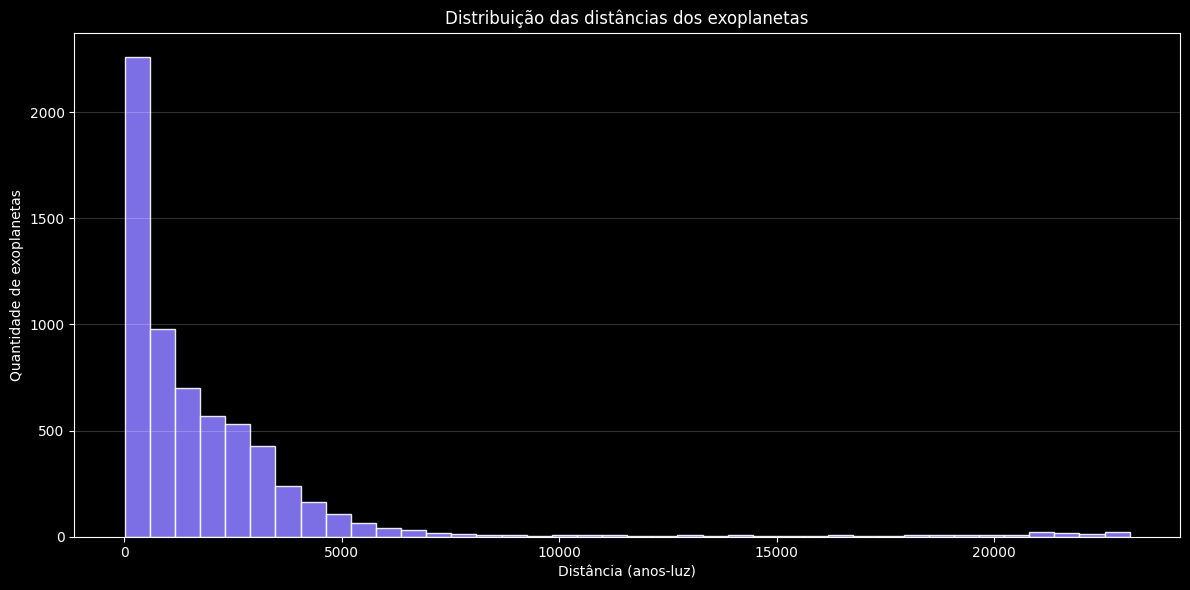

Registros no gráfico: 6358
Registros totais válidos: 6423


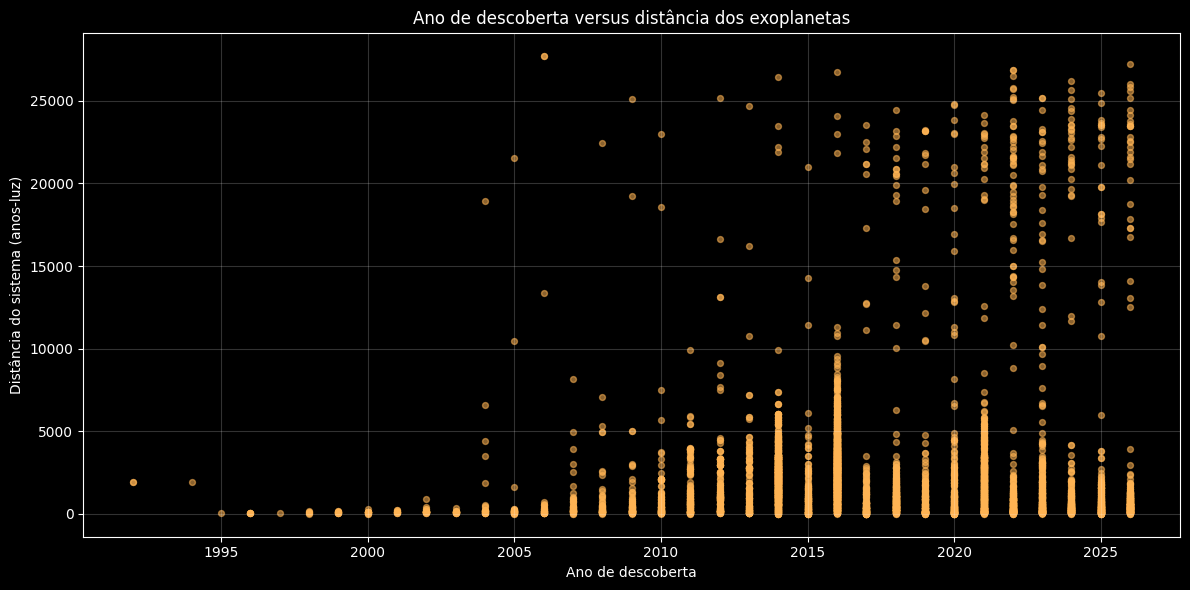

🌌 RESUMO DO EXODISTANCE
----------------------------------------
Planetas com distância válida: 6,423
Menor distância: 4.244 anos-luz
Distância mediana: 1,138.284 anos-luz
Maior distância: 27,723.260 anos-luz
Média: 2,298.856 anos-luz
Arquivo exportado: /kaggle/working/exodistance_resultados.csv
Total de registros: 6423


In [15]:

# Limitar a visualização aos 99% menores valores
# para evitar que distâncias extremas escondam os detalhes.
limite = df["distancia_anos_luz"].quantile(0.99)

dados_grafico = df[
    df["distancia_anos_luz"] <= limite
]

plt.figure(figsize=(12, 6))

plt.hist(
    dados_grafico["distancia_anos_luz"],
    bins=40,
    color="#8B7CFF",
    edgecolor="white",
    alpha=0.9
)

plt.xlabel("Distância (anos-luz)")
plt.ylabel("Quantidade de exoplanetas")
plt.title("Distribuição das distâncias dos exoplanetas")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Registros no gráfico: {len(dados_grafico)}")
print(f"Registros totais válidos: {len(df)}")


comparacao = df.dropna(
    subset=["disc_year", "distancia_anos_luz"]
).copy()

comparacao["disc_year"] = pd.to_numeric(
    comparacao["disc_year"], errors="coerce"
)

comparacao = comparacao.dropna(
    subset=["disc_year"]
)

plt.figure(figsize=(12, 6))

plt.scatter(
    comparacao["disc_year"],
    comparacao["distancia_anos_luz"],
    alpha=0.55,
    s=18,
    color="#FFB454"
)

plt.xlabel("Ano de descoberta")
plt.ylabel("Distância do sistema (anos-luz)")
plt.title("Ano de descoberta versus distância dos exoplanetas")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()



distancias = df["distancia_anos_luz"]

print("🌌 RESUMO DO EXODISTANCE")
print("-" * 40)
print(f"Planetas com distância válida: {len(df):,}")
print(f"Menor distância: {distancias.min():,.3f} anos-luz")
print(f"Distância mediana: {distancias.median():,.3f} anos-luz")
print(f"Maior distância: {distancias.max():,.3f} anos-luz")
print(f"Média: {distancias.mean():,.3f} anos-luz")



arquivo = "/kaggle/working/exodistance_resultados.csv"

df.to_csv(arquivo, index=False, encoding="utf-8")

print("Arquivo exportado:", arquivo)
print("Total de registros:", len(df))




## Fontes e metodologia

**Fonte:** NASA Exoplanet Archive — Planetary Systems
Composite Parameters (`pscomppars`).

**Documentação da API:**  
https://exoplanetarchive.ipac.caltech.edu/docs/TAP/usingTAP.html

**Definição das colunas:**  
https://exoplanetarchive.ipac.caltech.edu/docs/API_PS_columns.html

**Metodologia:**
- A distância original é obtida na coluna `sy_dist`, em parsecs.
- A conversão usa 1 parsec ≈ 3,26156 anos-luz.
- A distância corresponde ao sistema hospedeiro do exoplaneta.
- Registros sem distância válida são excluídos da análise.
- Os resultados dependem da versão do catálogo consultada.
